In [20]:
# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans



# Load the dataset
df = pd.read_csv('Mall_Customers.csv')

# Display the first 5 rows
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [21]:
# Overview of the dataset
df.info()

# Summary statistics for numerical columns
df.describe()

# Check for missing values
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [22]:
from sklearn.preprocessing import StandardScaler

# Select only numerical features relevant to clustering
features = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Apply StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Convert scaled features back into a DataFrame for readability
scaled_df = pd.DataFrame(scaled_features, columns=features.columns)

scaled_df.head()


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


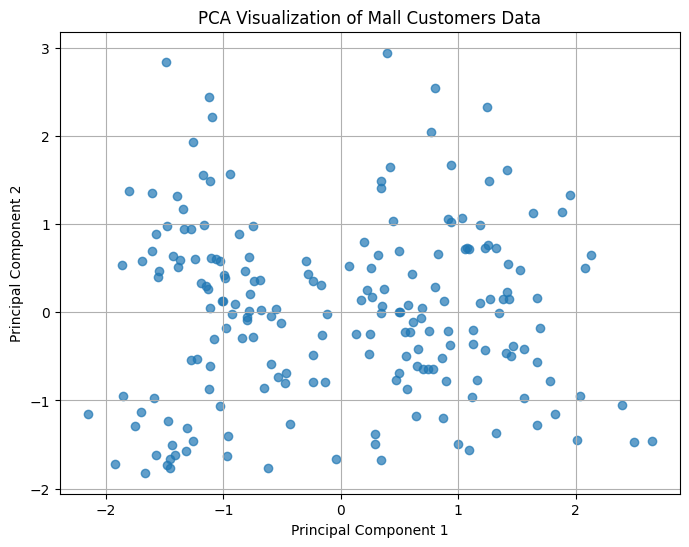

In [23]:
#b)
# Select features and standardize
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# Apply PCA
X_pca = PCA(n_components=2).fit_transform(X_scaled)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7)
plt.title('PCA Visualization of Mall Customers Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

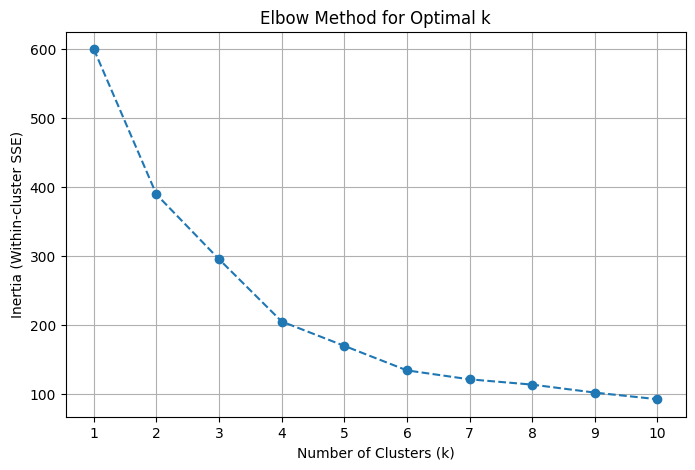

Inertia values: [599.9999999999999, 389.3861889564372, 295.4562449213556, 205.22514747675913, 169.89149793438582, 134.35277477401493, 121.38935022502872, 113.72723000071338, 102.13623844329254, 92.55027231838785]


In [24]:
#c
# Elbow Method
inertias = []
k_range = range(1, 11)  # Testing 1-10 clusters

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-cluster SSE)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Print inertia values for inspection
print("Inertia values:", inertias)

#K is equal to 6 based on the elbow method


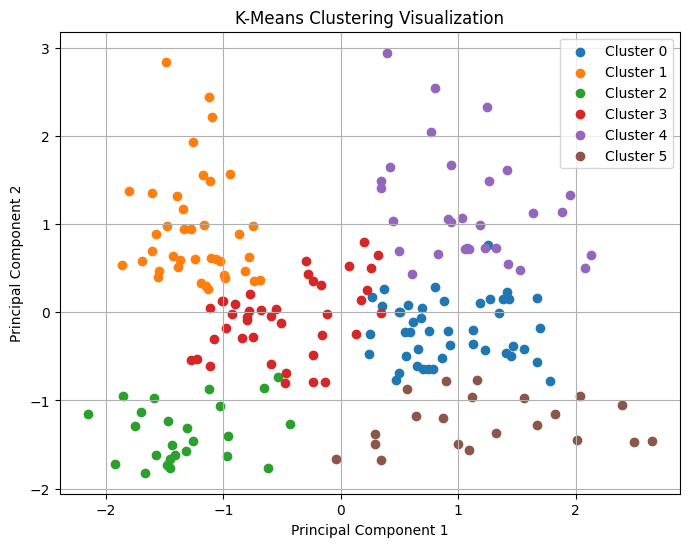

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,5
3,4,Female,23,16,77,2
4,5,Female,31,17,40,5


In [25]:
# d) Model Training with K-Means

# Train the K-Means model with the optimal number of clusters (k=6)
optimal_k = 6
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans.fit(X_scaled)

# Add the cluster labels to the original dataset
df['Cluster'] = kmeans.labels_

# Visualize the clusters in the PCA-reduced space
plt.figure(figsize=(8, 6))
for cluster in range(optimal_k):
    cluster_points = X_pca[df['Cluster'] == cluster]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], label=f'Cluster {cluster}')

plt.title('K-Means Clustering Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()

# Display the first few rows of the dataset with cluster labels
df.head()

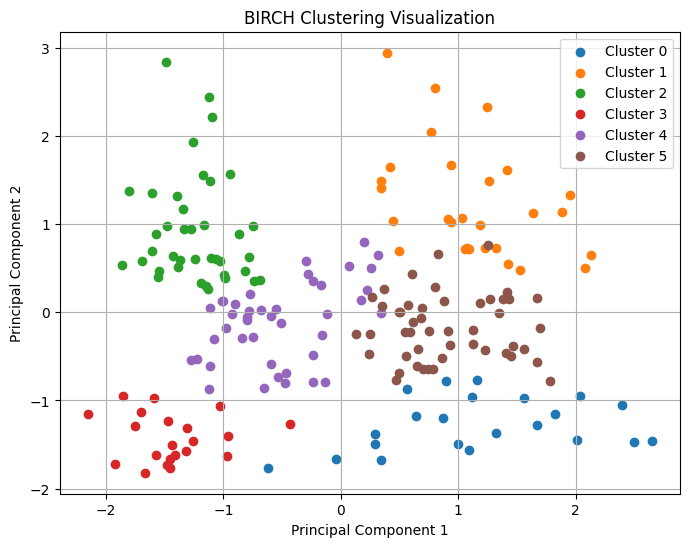

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster,BIRCH_Cluster
0,1,Male,19,15,39,2,0
1,2,Male,21,15,81,2,3
2,3,Female,20,16,6,5,0
3,4,Female,23,16,77,2,3
4,5,Female,31,17,40,5,0


In [26]:
# e.3) BIRCH Clustering

from sklearn.cluster import Birch

# Apply BIRCH with the same number of clusters as determined by the elbow method
birch = Birch(n_clusters=6)
birch.fit(X_scaled)

# Add the cluster labels to the original dataset
df['BIRCH_Cluster'] = birch.labels_

# Visualize the clusters in the PCA-reduced space
plt.figure(figsize=(8, 6))
for cluster in range(6):
    cluster_points = X_pca[df['BIRCH_Cluster'] == cluster]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], label=f'Cluster {cluster}')

plt.title('BIRCH Clustering Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()

# Display the first few rows of the dataset with BIRCH cluster labels
df.head()

In [27]:
#h)
# Interpretation: Interpret your findings
# i need all the steps el awel 